In [247]:
#Import libraries and define Symbols
import sympy as smp
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, RK45, BDF
from scipy.optimize import direct, Bounds
import time
from control import lqr, lqe

## Parameters

$C_D$ - Coefficient of Drag 

$C_L$ - Coefficient of Lift 

$S$ - Reference Area 

$I_{yy}$ - Pitching Moment

$T$ - Thrust curve (to be turned into function of time)

$m$ - Mass of rocket (to be turned into function of time)

$g$ - Acceleration due to gravity

$d_{CoP}$ - Distance from CoM to Center of Pressure

$d_{Noz}$ - Distance from CoM to Nozzle

$\rho$ - Density of air

In [123]:
#Parameters

Cd = 0.1
Cl = 0.01
S = 0.01

Iyy = 0.2705

T = 100
m = 7
g = 9.8
dCoP = 0.5
dNoz = 0.7
rho = 1.225

## Control Matrices

$$
A(t, \dot{z}) =
\begin{bmatrix}
0 & 0 & 1 & 0 & 0 & 0 \\[4pt]
0 & 0 & 0 & 1 & 0 & 0 \\[4pt]
0 & 0 & 0 & 0 & -g & 0 \\[4pt]
0 & 0 & 0 & -\dfrac{\rho S C_d}{m}|\dot{z}| & 0 & 0 \\[10pt]
0 & 0 & 0 & 0 & 0 & 1 \\[4pt]
0 & 0 & \dfrac{\rho S C_d d_{CoP}}{2I_{yy}}|\dot{z}| & 0 & -\dfrac{\rho S C_d d_{CoP}}{2I_{yy}}|\dot{z}|\dot{z} & 0
\end{bmatrix}

\\

B(t, \dot{z}) =
\begin{bmatrix}
0 & 0 \\[4pt]
0 & 0 \\[4pt]
 -g & 0 \\[4pt]
0 & -\dfrac{T}{m} \\[4pt]
0 & 0 \\[4pt]
\dfrac{d_{Noz} m g}{I_{yy}} & 0
\end{bmatrix}

$$

In [251]:
#Ascent Control matrices
def A(t, dz):
    a = np.zeros([6,6])
    a[0,2] = 1
    a[1,3] = 1
    a[2,4] = -g
    a[3,3] = -(rho*S*Cd)/(m) * np.abs(dz)
    a[4,5] = 1
    a[5,2] = (rho*S*Cd*dCoP)/(2*Iyy) * np.abs(dz)
    a[5,4] = -(rho*S*Cd*dCoP)/(2*Iyy) * np.abs(dz) * dz
    return a

def B(t, dz):
    b = np.zeros([6,2])
    b[2,0] = -g
    b[3,1] = -T/m
    b[5,0] = dNoz*m*g/Iyy
    return b

C = np.eye(6)
G = np.eye(6)
QN = np.eye(6)
RN = np.eye(6)

In [244]:
#Control Parameters

#Q and R matrices
Q = np.diag([1,10,1,200,10,10])
R = np.diag([0.001,0.1])

#Reference height trajectory
def z_ref(t):
    if t<20:
        return 100
    if t>20:
        return 0

def dz_ref(z,t):
    if (z<100 and t<20):
        return 10
    elif (z>100 and t<20):
        return 0
    elif (z>90 and t>20):
        return -10
    else:
        return 0

## Differential equation
$$

\begin{bmatrix}
    \dot{x} \\
    \dot{z} \\
    \ddot{x} \\
    \ddot{z} \\
    \dot{\theta} \\
    \ddot{\theta}
\end{bmatrix} 
= \begin{bmatrix}
    \dot{x} \\
    \dot{z} \\
    -\frac{\rho S C_D}{2m} \dot{x} \sqrt{\dot{x}^2 + \dot{z}^2} - \frac{(1-P)T}{m} \sin(\theta + \gamma)\\
    -\frac{\rho S C_D}{2m} \dot{z} \sqrt{\dot{x}^2 + \dot{z}^2} - \frac{(1-P)T}{m} \cos(\theta + \gamma)-g\\
    \dot{\theta} \\
    -\frac{\rho S C_D d_{CoP}}{2 I_{yy}} \left(\dot{x} \sqrt{\dot{x}^2 + \dot{z}^2} \cos(\theta)-\dot{z} \sqrt{\dot{x}^2 + \dot{z}^2} \sin(\theta)\right) + \frac{(1-P)T d_{Noz}}{I_{yy}} \sin(\gamma)\\
\end{bmatrix}

$$

## Differential equation
$$

\begin{bmatrix}
    \dot{x} \\
    \dot{z} \\
    \ddot{x} \\
    \ddot{z} \\
    \dot{\theta} \\
    \ddot{\theta}
\end{bmatrix} 
= \begin{bmatrix}
    \dot{x} \\
    \dot{z} \\
     - \frac{T}{m} \sin(\theta + \gamma)\\
     - \frac{T}{m} \cos(\theta + \gamma)-g\\
    \dot{\theta} \\
    \frac{T d_{Noz}}{I_{y}} \sin(\gamma)\\
\end{bmatrix}

$$

In [252]:
#DiffEq Solver (BDF)

# Define the system of ODEs
def system(t, State):
    x, z, dx, dz, theta, dtheta = State

    #LQR to find K
    At = A(t, dz)
    Bt = B(t, dz)
    K, Ric, Eig = lqr(At, Bt, Q, R)

    #Set control parameters
    global gamma
    global P
    gamma, P = -K @ [x, z-z_ref(t), dx, dz-dz_ref(z,t), theta, dtheta]

    #Kf = lqe(At,G,C,QN,RN)

    #Control limits
    
    #Throttle
    bP=1.0 #damping
    
    if len(t_vals) > 0:
        dt = t-t_vals[-1]
        dP = P-P_vals[-1]
        P = P_vals[-1] + np.clip((dP/dt),-10,10)*dt / bP #update P with damping
    P = np.clip(P,0,1) #min/max throttle

    #Gimbal
    bgamma = 1.0 #gimbal damping
    
    if len(t_vals) > 0:
        dt = t-t_vals[-1]
        dgamma = gamma-gamma_vals[-1]
        gamma = gamma_vals[-1] + np.clip((dgamma/dt),-500*2*np.pi, 500*2*np.pi)*dt / bgamma #update P with damping
    gamma = np.clip(gamma, -np.pi/2, np.pi/2) #min/max gimbal
    
    #No Control
    '''
    gamma = 0
    P = 0
    '''

    ddx = -(rho*S*Cd)/(2*m) * dx * np.sqrt(dx**2 + dz**2) - (1-P)*T/m * np.sin(theta + gamma)
    ddz = -(rho*S*Cd)/(2*m) * dz * np.sqrt(dx**2 + dz**2) + (1-P)*T/m * np.cos(theta + gamma) - g
    ddtheta = (rho*S*Cd*dCoP)/(2*Iyy) * (dx *  np.sqrt(dx**2 + dz**2) * np.cos(theta) - dz *  np.sqrt(dx**2 + dz**2) * np.sin(theta)) + (1-P)*dNoz*T/Iyy * np.sin(gamma)
    return [dx, dz, ddx, ddz, dtheta, ddtheta]

# Initial conditions
State0 = [0,1,0,0,0,1]

# Time span
t_span = (0, 40)

#Solution Data
t_vals, State_vals, gamma_vals, P_vals = [], [], [], []


#End status (0=full run, 1=took too long, 2=crashed)
status = 0

#Start Solver
start_time = time.time()
solver = BDF(system, t_span[0], State0, t_span[1])
while solver.status == "running":
    #Step solver and save data
    solver.step()
    t_vals.append(solver.t)
    State_vals.append(solver.y.copy())
    gamma_vals.append(gamma)
    P_vals.append(P)

    #End conditions
    if time.time() - start_time > 10:   
        solver.status = "stopped"       
        status = 1
        break
    if (State_vals[-1][1] < 0):
        solver.status = "stopped"    
        status = 2
        break

#Timestamped data
State_vals = np.array(State_vals).T

Status: 0
Final Height: 1.4758866524251872
Final Velocity: -0.32299706884002954


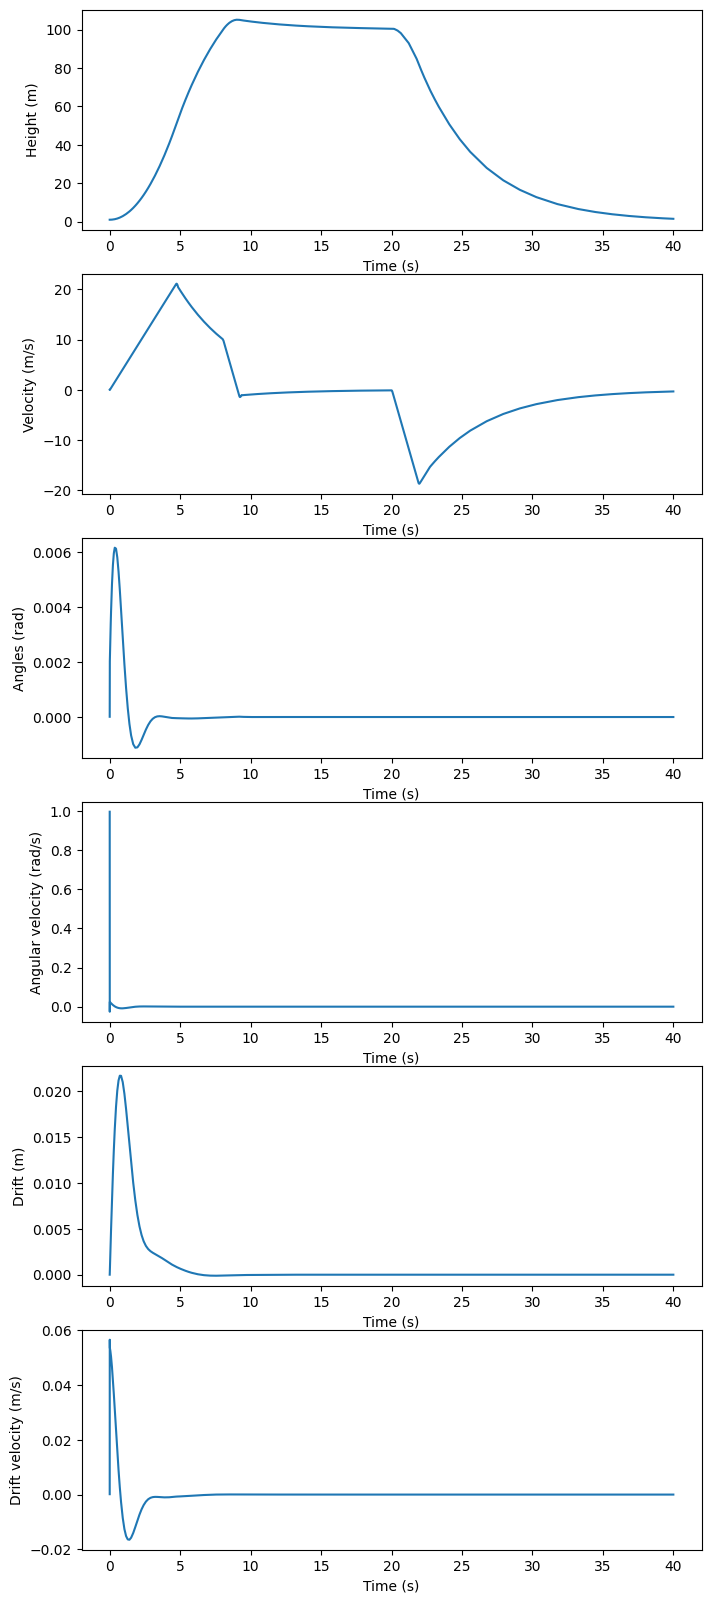

In [253]:
#Plot the trajectory
fig, ax = plt.subplots(nrows=6, ncols=1,figsize=(8, 20))
for i in range(6):
    ax[i].set_xlabel("Time (s)")

ax[0].plot(t_vals, State_vals[1])
ax[1].plot(t_vals, State_vals[3]) 
ax[2].plot(t_vals, State_vals[4])
ax[3].plot(t_vals, State_vals[5])
ax[4].plot(t_vals, State_vals[0])
ax[5].plot(t_vals, State_vals[2])

ax[0].set_ylabel("Height (m)")
ax[1].set_ylabel("Velocity (m/s)")
ax[2].set_ylabel("Angles (rad)")
ax[3].set_ylabel("Angular velocity (rad/s)")
ax[4].set_ylabel("Drift (m)")
ax[5].set_ylabel("Drift velocity (m/s)")

#Print status (0=full run, 1=took too long, 2=crashed)
print(f"Status: {status}")
print(f"Final Height: {State_vals[1][-1]}")
print(f"Final Velocity: {State_vals[3][-1]}")

#Show plots
plt.show() 

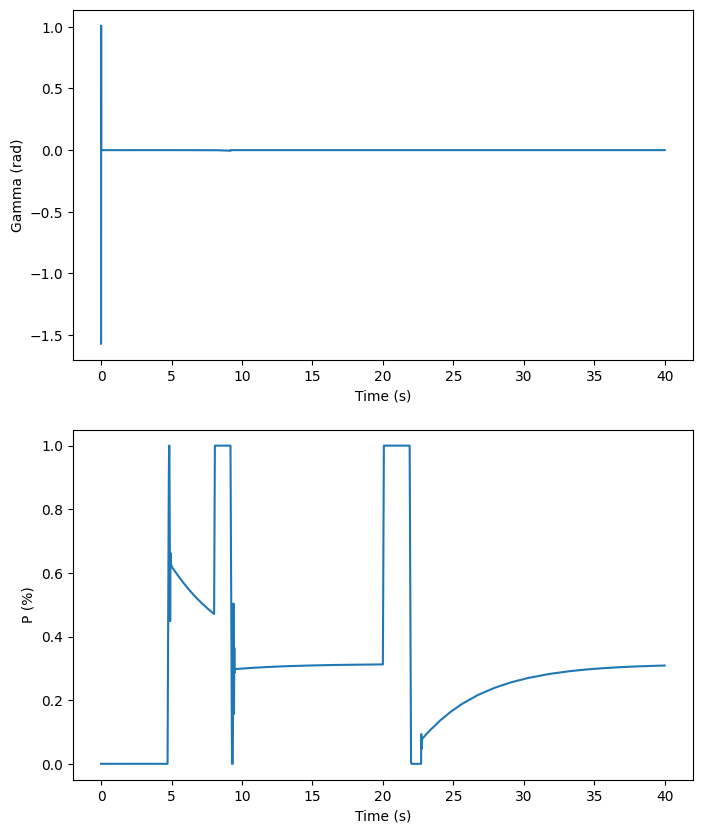

In [254]:
#Plot the control
fig, ax = plt.subplots(nrows=2, ncols=1,figsize=(8, 10))

ax[0].set_xlabel("Time (s)")
ax[1].set_xlabel("Time (s)")

ax[0].plot(t_vals, gamma_vals)
ax[1].plot(t_vals, P_vals)


ax[0].set_ylabel("Gamma (rad)")
ax[1].set_ylabel("P (%)")

#Show plots
plt.show()

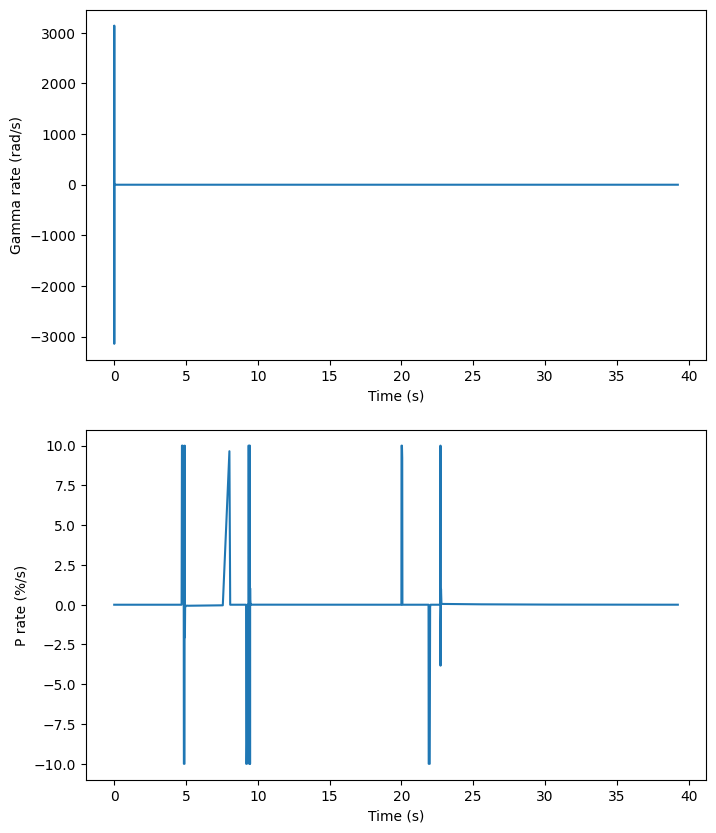

In [255]:
#Plot control rates
gamma_rate = [(gamma_vals[i+1]-gamma_vals[i])/(t_vals[i+1]-t_vals[i]) for i in range(len(t_vals)-1)]
P_rate = [(P_vals[i+1]-P_vals[i])/(t_vals[i+1]-t_vals[i]) for i in range(len(t_vals)-1)]

fig, ax = plt.subplots(nrows=2, ncols=1,figsize=(8, 10))

ax[0].set_xlabel("Time (s)")
ax[1].set_xlabel("Time (s)")

ax[0].plot(t_vals[:-1], gamma_rate)
ax[1].plot(t_vals[:-1], P_rate)


ax[0].set_ylabel("Gamma rate (rad/s)")
ax[1].set_ylabel("P rate (%/s)")

#Show plots
plt.show()
